# State-space control: balancing a pendulum on a cart

A pendulum stands upright on a cart that a motor pushes left and right. It
falls over on its own; a state-feedback controller designed by LQR keeps it
up and moves the cart. The plant is nonlinear (`ODE`), the controller a
matrix product (`FuncChunk`), the loop a plain line back. The linear theory
predicts the motion for small angles; the simulation shows where it stops
holding.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import solve_continuous_are
from scipy.signal import cont2discrete

import sigline as sl

## 1. The model

Cart mass $M$ at position $p$, a point mass $m$ on a light rod of length
$l$ (`ell` in the code) at angle $\theta$ from upright, force $F$ on the cart. With state
$x = (p, \dot p, \theta, \dot\theta)$, Lagrange's equations give

$$\ddot p = \frac{F + m \sin\theta\,(l\dot\theta^2 - g\cos\theta)}{M + m\sin^2\theta},
\qquad \ddot\theta = \frac{g \sin\theta - \ddot p \cos\theta}{l}.$$

Linearised at $\theta = 0$: $\dot x = Ax + BF$. The upright position has an
unstable eigenvalue $\lambda = \sqrt{(M+m)g/(Ml)}$: a small tilt grows as
$\theta_0 \cosh \lambda t$.

In [2]:
M, m, ell, g = 1.0, 0.2, 0.5, 9.81  # kg, kg, m, m/s^2


def cart(t, x, F):
    p, v, th, w = x
    s, c = np.sin(th), np.cos(th)
    a = (F + m * s * (ell * w**2 - g * c)) / (M + m * s**2)
    return [v, a, w, (g * s - a * c) / ell]


A = np.array(
    [
        [0, 1, 0, 0],
        [0, 0, -m * g / M, 0],
        [0, 0, 0, 1],
        [0, 0, (M + m) * g / (M * ell), 0],
    ]
)
B = np.array([[0.0], [1 / M], [0.0], [-1 / (M * ell)]])
lam = np.sqrt((M + m) * g / (M * ell))
print(f"eigenvalues of A: {np.round(np.linalg.eigvals(A), 3)}, lambda = {lam:.3f} 1/s")

eigenvalues of A: [ 0.   +0.j  0.   +0.j  4.852+0.j -4.852+0.j], lambda = 4.852 1/s


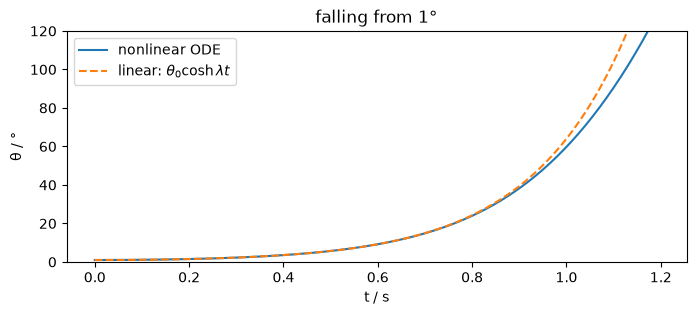

at 10° (t = 0.62 s) the linear model is off by 0.02°


In [3]:
fs = 200.0
plant = sl.ODE(cart, [0, 0, np.radians(1), 0], inputs=("F",), method="RK4", name="cart")
state = sl.Scope("state")
sl.Const(0.0, name="no force") >> plant >> state
d = sl.Diagram(state, fs=fs)
d.run(1.2)

theta = np.degrees(state.data[:, 2])
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(d.t, theta, label="nonlinear ODE")
ax.plot(d.t, np.cosh(lam * d.t), "--", label=r"linear: $\theta_0 \cosh \lambda t$")
ax.set(xlabel="t / s", ylabel="θ / °", ylim=(0, 120), title="falling from 1°")
ax.legend()
plt.show()
k = np.argmax(theta > 10)
print(
    f"at 10° (t = {d.t[k]:.2f} s) the linear model is off by "
    f"{np.cosh(lam * d.t[k]) - theta[k]:.2f}°"
)

## 2. LQR: balancing

LQR picks the gain $K$ in $F = -Kx$ that minimises
$\int x^\top Q x + R F^2\,dt$ for the linear model. $Q$ weights the angle
most, $R$ the force. `ODE(method="RK4")` integrates the plant for each held
force; the controller is a matrix product of the state.

Vector signals (the state) run in Python inside loops, not compiled;
`compile_loops="python"` says so instead of warning. Five seconds take
well under a second.

K = [-10.   -11.66 -73.54 -14.83]
closed-loop eigenvalues: [-7.68+3.33j -7.68-3.33j -1.33+1.02j -1.33-1.02j]


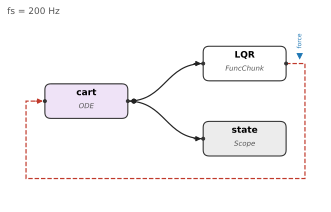

In [4]:
Q, Rw = np.diag([10.0, 1.0, 100.0, 1.0]), 0.1
P = solve_continuous_are(A, B, Q, np.array([[Rw]]))
K = (B.T @ P / Rw).ravel()
print("K =", np.round(K, 2))
print("closed-loop eigenvalues:", np.round(np.linalg.eigvals(A - B * K), 2))


def balance(theta0_deg, fs=200.0, target=0.0, fmax=None, T=5.0):
    x0 = [0.0, 0.0, np.radians(theta0_deg), 0.0]
    plant = sl.ODE(cart, x0, inputs=("F",), method="RK4", name="cart")
    lqr = sl.FuncChunk(
        lambda x, K=K, target=target: -((x - [target, 0, 0, 0]) @ K), name="LQR"
    )
    state = sl.Scope("state")
    if fmax is None:
        plant >> lqr >> plant
    else:
        (
            plant
            >> lqr
            >> sl.FuncChunk(lambda F, m=fmax: np.clip(F, -m, m), name="motor limit")
            >> plant
        )
    plant >> state
    d = sl.Diagram(state, fs=fs, compile_loops="python")
    force = d.probe(lqr, name="force")
    d.run(T)
    return d, state.data, force.data


d, x, F = balance(10.0)
d

The prediction: the linear plant held per sample (`cont2discrete`) under
the same feedback, $x[n+1] = (A_d - B_d K) x[n]$. From 1° the nonlinear
simulation follows it closely; from 10° and 25° the sine and cosine begin
to tell.

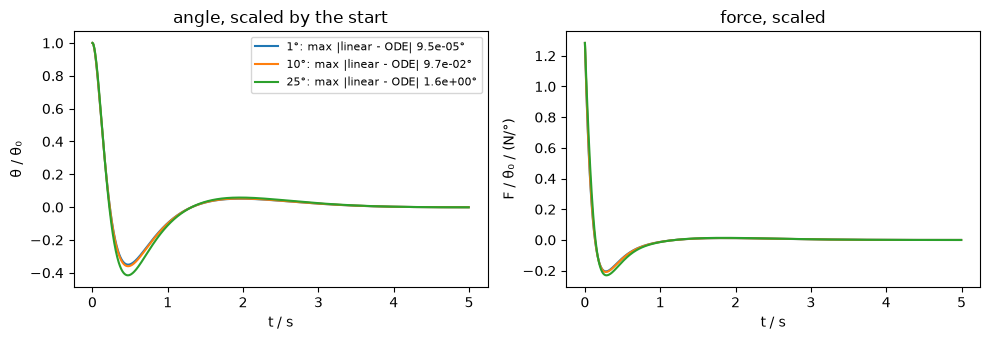

In [5]:
Ad, Bd, *_ = cont2discrete((A, B, np.eye(4), np.zeros((4, 1))), 1 / fs, "zoh")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.5))
for theta0 in (1.0, 10.0, 25.0):
    d, x, F = balance(theta0)
    lin = np.empty_like(x)
    lin[0] = [0, 0, np.radians(theta0), 0]
    for n in range(1, len(x)):
        lin[n] = (Ad - Bd * K) @ lin[n - 1]
    err = np.max(np.abs(np.degrees(x[:, 2] - lin[:, 2])))
    a1.plot(
        d.t,
        np.degrees(x[:, 2]) / theta0,
        label=f"{theta0:g}°: max |linear - ODE| {err:.1e}°",
    )
    a2.plot(d.t, F / theta0, label=f"{theta0:g}°")
a1.set(xlabel="t / s", ylabel="θ / θ₀", title="angle, scaled by the start")
a1.legend(fontsize=8)
a2.set(xlabel="t / s", ylabel="F / θ₀ / (N/°)", title="force, scaled")
fig.tight_layout()
plt.show()

## 3. Moving the cart

To move the cart to 1 m, feed back the error to the target state. The
cart first moves the wrong way: to go right, the pendulum must lean right,
so the cart pulls out from under it to the left. The plant is non-minimum
phase in $p$.

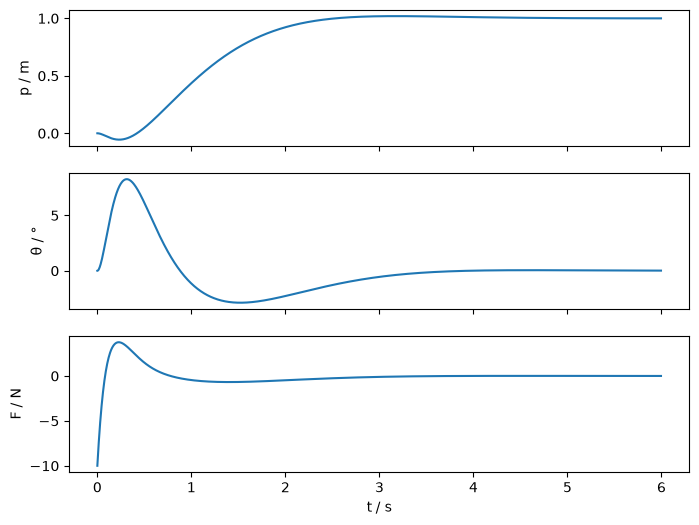

lowest position -5.5 cm, final 0.9997 m


In [6]:
d, x, F = balance(0.0, target=1.0, T=6.0)
fig, ax = plt.subplots(3, 1, figsize=(8, 6), sharex=True)
ax[0].plot(d.t, x[:, 0])
ax[0].set(ylabel="p / m")
ax[1].plot(d.t, np.degrees(x[:, 2]))
ax[1].set(ylabel="θ / °")
ax[2].plot(d.t, F)
ax[2].set(xlabel="t / s", ylabel="F / N")
plt.show()
print(f"lowest position {x[:, 0].min() * 100:.1f} cm, final {x[-1, 0]:.4f} m")

## 4. Limits: force and sample rate

A real motor gives a limited force. A sweep over the starting angle, as a
`for` loop: where does the pendulum still come back with $|F| \le$ 20 N?

In [7]:
angles = np.arange(5, 61, 5.0)
ok = []
for theta0 in angles:
    d, x, F = balance(theta0, fmax=20.0, T=6.0)
    ok.append(abs(x[-1, 2]) < np.radians(1) and abs(x[-1, 0]) < 0.1)
print("start   recovers with |F| <= 20 N")
for a, o in zip(angles, ok, strict=True):
    print(f"{a:4.0f}°   {'yes' if o else 'no'}")

start   recovers with |F| <= 20 N
   5°   yes
  10°   yes
  15°   yes
  20°   yes
  25°   yes
  30°   yes
  35°   yes
  40°   yes
  45°   yes
  50°   no
  55°   no
  60°   no


The controller was designed in continuous time. Running it at a lower rate
holds each force longer. The discrete closed loop $A_d - B_d K$ predicts
from which rate on it fails: when an eigenvalue leaves the unit circle.
A run that diverges ends in an error from the diagram's checks, which
name the block that produced inf.

In [8]:
print(" fs / Hz   max |eig(Ad - Bd K)|   simulated after 5 s")
for rate in (200.0, 50.0, 20.0, 10.0, 7.0, 5.0):
    Ad, Bd, *_ = cont2discrete((A, B, np.eye(4), np.zeros((4, 1))), 1 / rate, "zoh")
    rho = np.max(np.abs(np.linalg.eigvals(Ad - Bd * K)))
    try:
        with np.errstate(all="ignore"):
            d, x, F = balance(5.0, fs=rate)
        end = "balanced" if abs(x[-1, 2]) < np.radians(0.5) else "not balanced"
    except FloatingPointError:  # the diagram's check stops a run gone to inf
        end = "diverged"
    print(f"{rate:7.0f}   {rho:12.3f}            {end}")

 fs / Hz   max |eig(Ad - Bd K)|   simulated after 5 s


    200          0.993            balanced
     50          0.974            balanced
     20          0.937            balanced
     10          0.878            balanced
      7          1.845            diverged
      5          4.199            diverged


## Summary

- A nonlinear plant is an `ODE` with a vector state; its linearisation and
  LQR design come from SciPy, as on paper.
- State feedback is a `FuncChunk` with the gain as a parameter; references,
  limits and sweeps are one line or one `for` loop each.
- The simulation matches the linear prediction for small angles and shows
  where it stops holding: large angles, force limits, slow sampling.